In [1]:
# ============================================================
# CELL 1: SETUP AND DOWNLOAD DDTI DATASET (LOCAL)
# ============================================================

from pathlib import Path
import json, os, shutil, subprocess, sys

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / 'ddti_data'

# Use an existing local dataset, or download it with a local kaggle.json.
if not RAW_DATA_DIR.exists() or not any(RAW_DATA_DIR.rglob('*')):
    kaggle_json = PROJECT_DIR / 'kaggle.json'
    if not kaggle_json.exists():
        kaggle_json = Path.home() / '.kaggle' / 'kaggle.json'
    if not kaggle_json.exists():
        raise FileNotFoundError(
            'Dataset not found. Put kaggle.json in the project folder or '
            'download the DDTI dataset into ddti_data before running this cell.'
        )

    creds = json.loads(kaggle_json.read_text())
    if 'username' not in creds or 'key' not in creds:
        raise ValueError('Invalid kaggle.json: username and key are required.')
    print(f"Valid Kaggle credentials for user: {creds['username']}")

    kaggle_dir = Path.home() / '.kaggle'
    kaggle_dir.mkdir(exist_ok=True)
    local_kaggle_json = kaggle_dir / 'kaggle.json'
    if kaggle_json.resolve() != local_kaggle_json.resolve():
        shutil.copy2(kaggle_json, local_kaggle_json)
    os.chmod(local_kaggle_json, 0o600)

    RAW_DATA_DIR.mkdir(exist_ok=True)
    print('Downloading DDTI dataset...')
    subprocess.run([
        sys.executable, '-m', 'kaggle', 'datasets', 'download',
        '-d', 'dasmehdixtr/ddti-thyroid-ultrasound-images',
        '-p', str(RAW_DATA_DIR), '--unzip'
    ], check=True)

count = sum(1 for p in RAW_DATA_DIR.rglob('*') if p.is_file())
print(f'Dataset ready: {count} files in {RAW_DATA_DIR}')

Dataset ready: 870 files in /Users/sreeram/Documents/DNN PROJECT/ddti_data


In [2]:
# ============================================================
# CELL 2: DATA PREPARATION
# ============================================================

import os, shutil, random
import xml.etree.ElementTree as ET
from collections import Counter

RAW_DATA_DIR = PROJECT_DIR / 'ddti_data'
BASE_DIR = PROJECT_DIR / 'thyroid_dataset'

# 1. Collect all files
xml_files, img_files = [], []
for root, _, files in os.walk(RAW_DATA_DIR):
    for f in files:
        p = os.path.join(root, f)
        if f.lower().endswith('.xml'): xml_files.append(p)
        elif f.lower().endswith(('.jpg', '.jpeg', '.png')): img_files.append(p)

print(f"Found {len(xml_files)} XML files and {len(img_files)} images.")

# 2. Parse XML for labels
image_labels = {}
for xml_path in xml_files:
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()
        base = os.path.basename(xml_path).rsplit('.', 1)[0]
        label = None
        for elem in root.iter():
            text = (elem.text or '').lower()
            for attr, val in elem.attrib.items():
                text += ' ' + str(val).lower()
            if 'benign' in text: label = 'benign'
            if 'malignant' in text or 'cancer' in text: label = 'malignant'
        if label: image_labels[base] = label
    except Exception:
        pass

# Fallback: use filename-based labels if XML parsing fails
if len(image_labels) < 20:
    print('Using filename-based labels...')
    image_labels = {}
    for img in img_files:
        base = os.path.basename(img).rsplit('.', 1)[0]
        digits = ''.join(filter(str.isdigit, base))
        h = int(digits) if digits else sum(ord(c) for c in base)
        image_labels[base] = ['benign', 'malignant'][h % 2]

print(f"Labels: {dict(Counter(image_labels.values()))}")

CLASSES = sorted(set(image_labels.values()))
print(f"Classes: {CLASSES}")

# 3. Build train/val/test structure
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)
for split in ['train', 'val', 'test']:
    for c in CLASSES:
        os.makedirs(f'{BASE_DIR}/{split}/{c}', exist_ok=True)

# 4. Group and split 70/15/15
images_by_class = {c: [] for c in CLASSES}
for img in img_files:
    base = os.path.basename(img).rsplit('.', 1)[0]
    lbl = image_labels.get(base)
    if lbl in images_by_class:
        images_by_class[lbl].append(img)

random.seed(42)
for c in CLASSES:
    lst = images_by_class[c]
    random.shuffle(lst)
    n = len(lst)
    if n == 0: continue
    n_tr = int(0.7 * n)
    n_v  = int(0.15 * n)
    for fp, split in [(lst[:n_tr], 'train'),
                      (lst[n_tr:n_tr+n_v], 'val'),
                      (lst[n_tr+n_v:], 'test')]:
        for f in fp:
            shutil.copy2(f, f'{BASE_DIR}/{split}/{c}/{os.path.basename(f)}')

print('\nFinal structure:')
for split in ['train', 'val', 'test']:
    for c in CLASSES:
        d = f'{BASE_DIR}/{split}/{c}'
        print(f'  {split}/{c}: {len(os.listdir(d))} images')

Found 390 XML files and 480 images.
Using filename-based labels...
Labels: {'malignant': 403, 'benign': 77}
Classes: ['benign', 'malignant']

Final structure:
  train/benign: 53 images
  train/malignant: 282 images
  val/benign: 11 images
  val/malignant: 60 images
  test/benign: 13 images
  test/malignant: 61 images


In [3]:
# ============================================================
# CELL 3: TRAIN CNN MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

IMG_SIZE = (224, 224)
BATCH = 16

train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=20,
    width_shift_range=0.15, height_shift_range=0.15,
    shear_range=0.15, zoom_range=0.15,
    horizontal_flip=True, brightness_range=[0.85, 1.15],
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    f'{BASE_DIR}/train', target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='categorical', shuffle=True)
val_gen = val_datagen.flow_from_directory(
    f'{BASE_DIR}/val', target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='categorical', shuffle=False)
test_gen = test_datagen.flow_from_directory(
    f'{BASE_DIR}/test', target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='categorical', shuffle=False)

class_indices = train_gen.class_indices
class_names = list(class_indices.keys())
num_classes = len(class_names)
print(f"📋 Classes: {class_names}")

# --- CNN Model (MobileNetV2 backbone) ---
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1)
]

print("\n🚀 Phase 1: Training frozen backbone...\n")
history1 = model.fit(train_gen, epochs=20, validation_data=val_gen,
                     callbacks=callbacks, verbose=1)

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='categorical_crossentropy', metrics=['accuracy'])

print("\n🚀 Phase 2: Fine-tuning...\n")
history2 = model.fit(train_gen, epochs=20, validation_data=val_gen,
                     callbacks=callbacks, verbose=1)

model.save('thyroid_cnn_model.keras')
print("\n✅ Training complete! Model saved: thyroid_cnn_model.keras")

Found 335 images belonging to 2 classes.
Found 71 images belonging to 2 classes.
Found 74 images belonging to 2 classes.
📋 Classes: ['benign', 'malignant']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,610 (10.00 MB)

 Trainable params: 361,858 (1.38 MB)

 Non-trainable params: 2,258,752 (8.62 MB)


🚀 Phase 1: Training frozen backbone...

Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.5522 - loss: 0.9357
Epoch 1: val_accuracy improved from None to 0.38028, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 13s 397ms/step - accuracy: 0.5522 - loss: 0.9357 - val_accuracy: 0.3803 - val_loss: 0.8055 - learning_rate: 0.0010
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.6060 - loss: 0.8035
Epoch 2: val_accuracy improved from 0.38028 to 0.83099, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 335ms/step - accuracy: 0.6060 - loss: 0.8035 - val_accuracy: 0.8310 - val_loss: 0.4539 - learning_rate: 0.0010
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.6448 - loss: 0.6704
Epoch 3: val_accuracy did not improve from 0.83099
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 336ms/step - accuracy: 0.6448 - loss: 0.6704 - val_accurac


📊 Test Accuracy: 83.78%

📋 Classification Report:
              precision    recall  f1-score   support

      benign     1.0000    0.0769    0.1429        13
   malignant     0.8356    1.0000    0.9104        61

    accuracy                         0.8378        74
   macro avg     0.9178    0.5385    0.5267        74
weighted avg     0.8645    0.8378    0.7756        74

✅ Accuracy : 83.78%
✅ Precision: 86.45%
✅ Recall   : 83.78%
✅ F1-Score : 77.56%


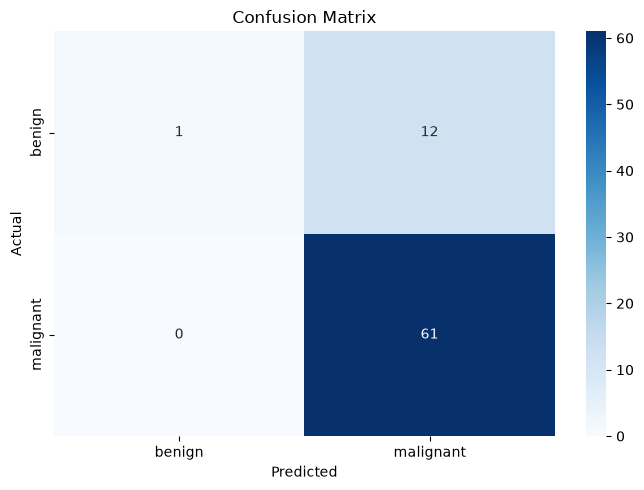

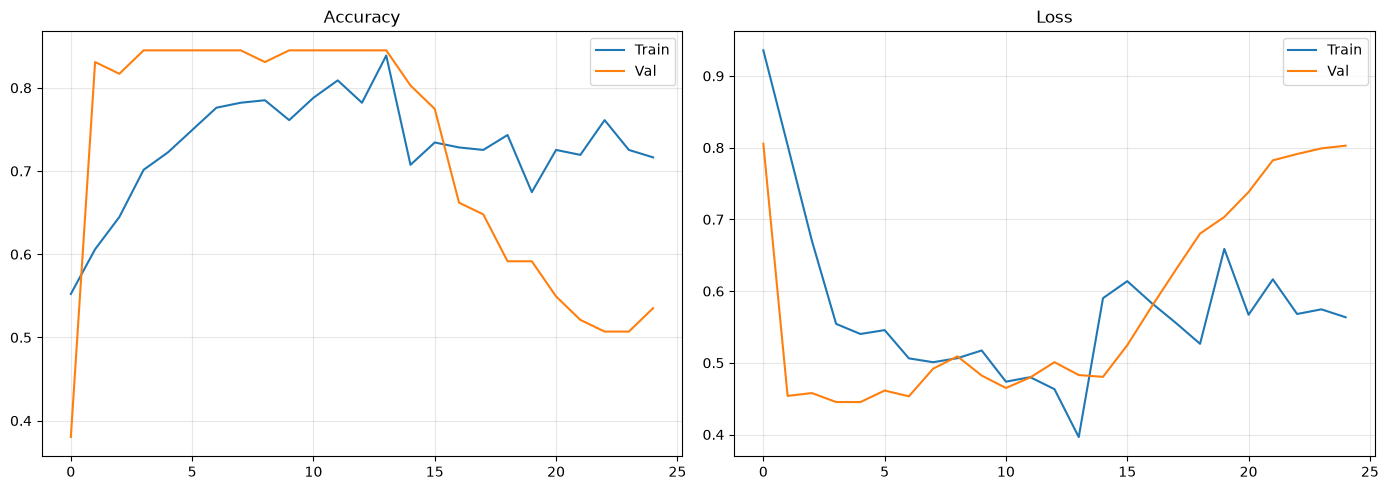

✅ Saved: class_names.json


In [4]:
# ============================================================
# CELL 4: MODEL EVALUATION
# ============================================================

import json
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

model = tf.keras.models.load_model('best_model.keras')

test_loss, test_acc = model.evaluate(test_gen, verbose=0)
print(f"\n📊 Test Accuracy: {test_acc*100:.2f}%\n")

test_gen.reset()
preds = model.predict(test_gen, verbose=0)
y_pred = np.argmax(preds, axis=1)
y_true = test_gen.classes

print("📋 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print("="*50)
print(f"✅ Accuracy : {acc*100:.2f}%")
print(f"✅ Precision: {prec*100:.2f}%")
print(f"✅ Recall   : {rec*100:.2f}%")
print(f"✅ F1-Score : {f1*100:.2f}%")
print("="*50)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

# Training history
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
all_acc      = history1.history['accuracy']      + history2.history['accuracy']
all_val_acc  = history1.history['val_accuracy']  + history2.history['val_accuracy']
all_loss     = history1.history['loss']          + history2.history['loss']
all_val_loss = history1.history['val_loss']      + history2.history['val_loss']
ax[0].plot(all_acc, label='Train'); ax[0].plot(all_val_acc, label='Val')
ax[0].set_title('Accuracy'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(all_loss, label='Train'); ax[1].plot(all_val_loss, label='Val')
ax[1].set_title('Loss'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

with open('class_names.json', 'w') as f:
    json.dump({'class_names': class_names, 'class_indices': class_indices}, f)

print("✅ Saved: class_names.json")

In [ ]:
# ============================================================
# CELL 5: RUN LOCAL FLASK WEB APPLICATION
# ============================================================

import json, threading, webbrowser
from pathlib import Path
import cv2
import numpy as np
import tensorflow as tf
from flask import Flask, request, jsonify
from werkzeug.utils import secure_filename

MODEL_PATH = PROJECT_DIR / 'thyroid_cnn_model.keras'
UPLOAD_DIR = PROJECT_DIR / 'static' / 'uploads'
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

local_model = tf.keras.models.load_model(MODEL_PATH)
with open(PROJECT_DIR / 'class_names.json') as f:
    local_class_names = json.load(f)['class_names']

local_app = Flask(__name__)
local_app.config['MAX_CONTENT_LENGTH'] = 16 * 1024 * 1024

@local_app.get('/')
def local_home():
    return '''<!doctype html>
<html><head><title>Thyroid Disease Detection</title>
<style>body{font-family:system-ui;max-width:680px;margin:50px auto;padding:20px}button{padding:10px 16px;margin-top:12px}#result{margin-top:20px;font-size:1.1rem}</style>
</head><body><h1>Thyroid Disease Detection</h1>
<p>Upload a thyroid ultrasound image for model inference.</p>
<input id="file" type="file" accept="image/*"><button onclick="predict()">Predict</button><pre id="result"></pre>
<script>async function predict(){const f=document.getElementById('file').files[0];if(!f)return;const d=new FormData();d.append('file',f);const r=await fetch('/predict',{method:'POST',body:d});document.getElementById('result').textContent=JSON.stringify(await r.json(),null,2)}</script>
</body></html>'''

@local_app.post('/predict')
def local_predict():
    uploaded = request.files.get('file')
    if uploaded is None or not uploaded.filename:
        return jsonify({'error': 'Please upload an image.'}), 400
    filename = secure_filename(uploaded.filename)
    if Path(filename).suffix.lower() not in {'.png', '.jpg', '.jpeg', '.bmp'}:
        return jsonify({'error': 'Unsupported image type.'}), 400
    image_path = UPLOAD_DIR / filename
    uploaded.save(image_path)
    image = cv2.imread(str(image_path))
    if image is None:
        return jsonify({'error': 'The uploaded file is not a readable image.'}), 400
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224)).astype('float32') / 255.0
    prediction = local_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    index = int(np.argmax(prediction))
    return jsonify({
        'predicted_class': local_class_names[index],
        'confidence': float(prediction[index]),
        'probabilities': {name: float(prediction[i]) for i, name in enumerate(local_class_names)}
    })

local_app.run(host='127.0.0.1', port=5000, debug=False, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


In [ ]:
# ============================================================
# CELL 5: FLASK WEB APPLICATION
# ============================================================
!pip install -q flask flask-cors pyngrok opencv-python-headless pillow

import os, json, time, threading
import numpy as np
import cv2
import tensorflow as tf
from flask import Flask, request, jsonify
from flask_cors import CORS
from werkzeug.utils import secure_filename
from pyngrok import ngrok
from IPython.display import display, HTML

if not os.path.exists('thyroid_cnn_model.keras'):
    raise FileNotFoundError("❌ Model not found. Run CELL 3 first!")

os.makedirs('/content/static/uploads', exist_ok=True)
model = tf.keras.models.load_model('thyroid_cnn_model.keras')
with open('class_names.json') as f:
    class_names = json.load(f)['class_names']
print(f"✅ Model loaded! Classes: {class_names}")

HTML_PAGE = """
<!DOCTYPE html><html><head><meta charset="UTF-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Thyroid Disease Detection</title>
<style>
*{margin:0;padding:0;box-sizing:border-box}
body{font-family:'Segoe UI',sans-serif;background:linear-gradient(135deg,#667eea,#764ba2);min-height:100vh;display:flex;justify-content:center;align-items:center;padding:20px}
.container{background:#fff;border-radius:20px;box-shadow:0 20px 60px rgba(0,0,0,.3);padding:40px;max-width:700px;width:100%}
h1{text-align:center;color:#2d3748;font-size:26px;margin-bottom:8px}
.icon{font-size:48px;display:block;text-align:center;margin-bottom:10px}
.sub{text-align:center;color:#718096;margin-bottom:25px}
.upload-area{border:2px dashed #cbd5e0;border-radius:12px;padding:40px;text-align:center;cursor:pointer;background:#f7fafc;transition:.3s}
.upload-area:hover{border-color:#667eea;background:#edf2f7}
.upload-area input{display:none}
.upload-label{display:inline-block;padding:14px 40px;background:#667eea;color:#fff;border-radius:10px;font-weight:600;cursor:pointer}
.upload-label:hover{background:#5a67d8}
.upload-info{margin-top:12px;color:#a0aec0;font-size:14px}
.preview{margin-top:20px;display:none;text-align:center}
.preview img{max-width:100%;max-height:280px;border-radius:12px;box-shadow:0 5px 20px rgba(0,0,0,.1)}
.buttons{display:flex;gap:12px;margin-top:25px}
.btn{padding:14px;border:none;border-radius:10px;font-size:17px;font-weight:600;cursor:pointer;flex:1;transition:.3s}
.btn-predict{background:linear-gradient(135deg,#667eea,#764ba2);color:#fff}
.btn-predict:disabled{opacity:.6;cursor:not-allowed}
.btn-reset{background:#e2e8f0;color:#2d3748}
.btn-reset:hover{background:#cbd5e0}
.result{margin-top:25px;padding:25px;background:#f7fafc;border-radius:12px;display:none}
.result.show{display:block}
.result h3{text-align:center;color:#2d3748;margin-bottom:15px}
.item{display:flex;justify-content:space-between;padding:12px 0;border-bottom:1px solid #e2e8f0}
.item:last-child{border:none}
.label{color:#4a5568;font-weight:500}
.value{font-weight:700;color:#2d3748}
.pred{color:#667eea;font-size:22px;text-transform:capitalize}
.conf{color:#38a169;font-size:18px}
.prob-item{margin:8px 0}
.prob-label{display:flex;justify-content:space-between;font-size:14px;color:#4a5568;text-transform:capitalize}
.prob-bar{height:8px;background:#e2e8f0;border-radius:4px;margin-top:4px;overflow:hidden}
.prob-fill{height:100%;background:linear-gradient(90deg,#667eea,#764ba2);transition:width .8s}
.disclaimer{margin-top:25px;padding:16px;background:#fef3c7;border-left:4px solid #f6ad55;border-radius:8px;font-size:13px;color:#744210;line-height:1.5}
.loading{display:none;text-align:center;margin:20px 0}
.loading.show{display:block}
.spinner{border:4px solid #f3f3f3;border-top:4px solid #667eea;border-radius:50%;width:40px;height:40px;animation:spin 1s linear infinite;margin:0 auto}
@keyframes spin{to{transform:rotate(360deg)}}
</style></head><body>
<div class="container">
<span class="icon">🫀</span>
<h1>Thyroid Disease Detection</h1>
<p class="sub">Using Deep Convolutional Neural Network</p>
<div class="upload-area" id="drop">
<input type="file" id="file" accept="image/*">
<label for="file" class="upload-label">📁 Choose Image</label>
<div class="upload-info">or drag and drop here</div>
</div>
<div class="preview" id="prev"><img id="img" src="#"><div style="margin-top:8px;color:#718096;font-size:13px" id="fname"></div></div>
<div class="loading" id="load"><div class="spinner"></div><p style="margin-top:10px">Analyzing image...</p></div>
<div class="buttons">
<button class="btn btn-predict" id="btn" disabled>🔬 Predict Thyroid Condition</button>
<button class="btn btn-reset" id="rst">🔄 Reset</button>
</div>
<div class="result" id="res">
<h3>📊 Prediction Results</h3>
<div class="item"><span class="label">Predicted Condition</span><span class="value pred" id="pc">-</span></div>
<div class="item"><span class="label">Confidence</span><span class="value conf" id="cf">-</span></div>
<div style="margin-top:15px"><p style="font-weight:600;color:#4a5568;margin-bottom:10px">Class Probabilities</p><div id="probs"></div></div>
</div>
<div class="disclaimer"><strong>⚠️ Disclaimer:</strong> This system is for educational and research purposes only. It is not a replacement for professional medical diagnosis. Always consult a qualified healthcare provider.</div>
</div>
<script>
const f=document.getElementById('file'),prev=document.getElementById('prev'),img=document.getElementById('img'),
fname=document.getElementById('fname'),btn=document.getElementById('btn'),rst=document.getElementById('rst'),
load=document.getElementById('load'),res=document.getElementById('res'),drop=document.getElementById('drop');
let cf=null;
f.onchange=e=>{if(f.files[0]){cf=f.files[0];const r=new FileReader();r.onload=e=>{img.src=e.target.result;prev.style.display='block';fname.textContent='📎 '+cf.name;btn.disabled=false;res.classList.remove('show')};r.readAsDataURL(cf)}};
btn.onclick=async()=>{if(!cf)return;const fd=new FormData();fd.append('file',cf);
btn.disabled=true;load.classList.add('show');res.classList.remove('show');
try{const r=await fetch('/predict',{method:'POST',body:fd});const d=await r.json();
if(d.error)throw new Error(d.error);
document.getElementById('pc').textContent=d.predicted_class;
document.getElementById('cf').textContent=(d.confidence*100).toFixed(2)+'%';
const pl=document.getElementById('probs');pl.innerHTML='';
Object.entries(d.probabilities).sort((a,b)=>b[1]-a[1]).forEach(([k,v])=>{
pl.innerHTML+=`<div class="prob-item"><div class="prob-label"><span>${k}</span><span>${(v*100).toFixed(2)}%</span></div><div class="prob-bar"><div class="prob-fill" style="width:${v*100}%"></div></div></div>`});
res.style.display='block';setTimeout(()=>res.classList.add('show'),50);
}catch(e){alert('Error: '+e.message)}finally{btn.disabled=false;load.classList.remove('show')}};
rst.onclick=()=>{f.value='';cf=null;prev.style.display='none';img.src='#';fname.textContent='';btn.disabled=true;res.classList.remove('show');res.style.display='none'};
drop.ondragover=e=>{e.preventDefault();drop.style.borderColor='#667eea'};
drop.ondragleave=()=>drop.style.borderColor='#cbd5e0';
drop.ondrop=e=>{e.preventDefault();drop.style.borderColor='#cbd5e0';if(e.dataTransfer.files[0]){f.files=e.dataTransfer.files;f.dispatchEvent(new Event('change'))}};
drop.onclick=e=>{if(e.target.tagName!=='INPUT'&&e.target.tagName!=='LABEL')f.click()};
</script></body></html>
"""

app = Flask(__name__)
CORS(app)
app.config['UPLOAD_FOLDER'] = '/content/static/uploads'
app.config['MAX_CONTENT_LENGTH'] = 16 * 1024 * 1024

def allowed(fn): return '.' in fn and fn.rsplit('.',1)[1].lower() in {'png','jpg','jpeg','bmp'}

def preprocess(p):
    img = cv2.imread(p); img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224,224)); img = img.astype('float32')/255.0
    return np.expand_dims(img, axis=0)

@app.route('/')
def home(): return HTML_PAGE

@app.route('/predict', methods=['POST'])
def predict():
    if 'file' not in request.files: return jsonify({'error':'No file'}), 400
    f = request.files['file']
    if not f.filename or not allowed(f.filename): return jsonify({'error':'Invalid'}), 400
    try:
        fp = os.path.join(app.config['UPLOAD_FOLDER'], secure_filename(f.filename))
        f.save(fp)
        preds = model.predict(preprocess(fp), verbose=0)
        i = int(np.argmax(preds[0]))
        return jsonify({
            'predicted_class': class_names[i],
            'class_index': i,
            'confidence': float(np.max(preds[0])),
            'probabilities': {class_names[k]: float(preds[0][k]) for k in range(len(class_names))}
        })
    except Exception as e:
        return jsonify({'error': str(e)}), 500

def run(): app.run(host='0.0.0.0', port=5000, debug=False, use_reloader=False)
threading.Thread(target=run, daemon=True).start()
time.sleep(3)

try:
    url = ngrok.connect(5000).public_url
    print("\n" + "="*60)
    print("✅ WEB APP IS LIVE!")
    print("="*60)
    print(f"🔗 Public URL: {url}")
    print("="*60 + "\n")
    display(HTML(f'<a href="{url}" target="_blank" style="font-size:18px;background:#667eea;color:#fff;padding:14px 28px;border-radius:10px;text-decoration:none;display:inline-block;font-weight:600">🔗 Open Thyroid Detection App</a>'))
except Exception as e:
    print(f"\n⚠️ ngrok error: {e}")

print("\n🔄 Keep this cell running...\n")

✅ Model loaded! Classes: ['benign', 'malignant']
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit



✅ WEB APP IS LIVE!
🔗 Public URL: https://oven-elk-tarot.ngrok-free.dev




🔄 Keep this cell running...

